## Importing Libraries

In [20]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

### Loading Model

In [21]:
model  = tf.keras.models.load_model('trained_model.keras')

In [22]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 conv2d_1 (Conv2D)           (None, 126, 126, 32)      9248      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 63, 63, 32)       0         
 )                                                               
                                                                 
 conv2d_2 (Conv2D)           (None, 63, 63, 64)        18496     
                                                                 
 conv2d_3 (Conv2D)           (None, 61, 61, 64)        36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 30, 30, 64)       0         
 2D)                                                    

### Visualizaing Single Image of Test set

In [23]:
!pip install opencv-python

In [ ]:
import cv2
image_path = "\test\test\TomatoEarlyBlight2.JPG"
#Reading Image
img = cv2.imread(image_path)
img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB) #Convert BGR image to RGB

#Displaying Image
plt.imshow(img)
plt.title("Test Image")
plt.xticks([])
plt.yticks([])
plt.show()

error: OpenCV(4.11.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


## Testing Model

In [22]:
image = tf.keras.preprocessing.image.load_img(image_path,target_size=(128, 128))
input_arr = tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.array([input_arr]) #Convert single image to a batch
print(input_arr.shape)

(1, 128, 128, 3)


In [23]:
prediction = model.predict(input_arr)
prediction,prediction.shape

1/1 [==============================] - 6s 6s/step


(array([[1.6333686e-11, 1.1661900e-11, 1.0000000e+00, 5.4817696e-14,
         3.3971367e-11, 9.6484166e-12, 7.2788853e-15, 4.1720256e-08,
         2.0755706e-15, 1.9661325e-13, 7.3757453e-20, 3.3453579e-10,
         3.4092198e-13, 4.3298558e-15, 5.1370621e-13, 5.3733775e-13,
         9.2583781e-11, 5.1801062e-14, 8.1625651e-10, 1.9436943e-12,
         5.4899158e-12, 4.1083033e-14, 6.8509413e-13, 3.7798066e-13,
         4.8676834e-16, 1.9434995e-14, 2.8989021e-13, 8.2053421e-16,
         1.2681359e-09, 5.2482275e-11, 1.3321526e-12, 4.4193640e-16,
         5.8835545e-12, 1.7782219e-17, 5.9050052e-12, 1.5604131e-14,
         1.0688652e-14, 1.3747562e-13]], dtype=float32),
 (1, 38))

In [24]:
result_index = np.argmax(prediction)
result_index

2

In [25]:
class_name = ['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_spider_mite',
 'Tomato___Target_Spot',
 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 'Tomato___Tomato_mosaic_virus',
 'Tomato___healthy']

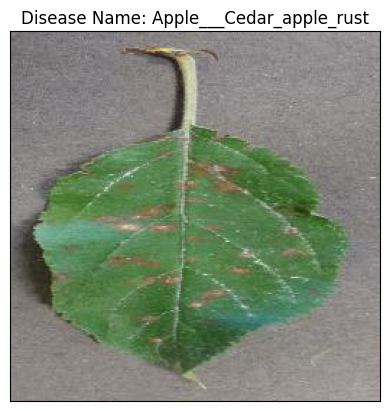

In [26]:
#Displaying Result of disease prediction
model_prediction = class_name[result_index]
plt.imshow(img)
plt.title(f"Disease Name: {model_prediction}")
plt.xticks([])
plt.yticks([])
plt.show()

In [27]:
model_prediction

'Apple___Cedar_apple_rust'